# Tarea Computacional · IMT2220 Cálculo para Ciencia de Datos (2026-2)
## Problema 2: Red neuronal con dos capas ocultas

**Grupo:** 2

**Integrantes:**
- Alondra Estay
- Gaspar Galaz
- José Mora
- Renato Reyes

---

**Antes de entregar**
- Ejecuten todas las celdas en orden, de principio a fin (*Reiniciar kernel y ejecutar todo*), y revisen que no haya errores.
- Solo pueden usar operaciones básicas de `numpy`, funciones para leer los datos y `matplotlib` (ver *Indicaciones para el código* en el enunciado). 
- Los desarrollos y las respuestas van en el informe (PDF). Aquí basta con el código, sus resultados y comentarios breves.
- Para obtener el PDF: en VS Code, menú `···` de la barra superior del notebook → *Exportar* → *HTML*; luego abran el `.html` en el navegador e imprímanlo como PDF.

Reemplacen cada celda marcada con `# TODO` por su código. Pueden agregar todas las celdas que necesiten.

## Configuración

In [29]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("figuras", exist_ok=True)   # aquí se guardan las figuras para el informe

## Datos

Los archivos `datos_P2.csv` (partes (c) a (f)) y `datos_P2_g.csv` (parte (g)) deben estar en la misma carpeta que este notebook. Tienen una línea de encabezado `x,y` y dos columnas separadas por comas.

N = 200 datos;  x en [-0.990, 0.966],  y en [-0.077, 2.216]


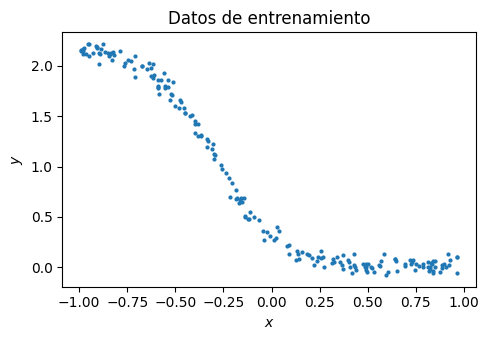

In [30]:
x, y = np.loadtxt("datos_P2.csv", delimiter=",", skiprows=1, unpack=True)
x_g, y_g = np.loadtxt("datos_P2_g.csv", delimiter=",", skiprows=1, unpack=True)
N = len(x)
print(f"N = {N} datos;  x en [{x.min():.3f}, {x.max():.3f}],  y en [{y.min():.3f}, {y.max():.3f}]")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(x, y, ".", ms=4)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Datos de entrenamiento")
fig.tight_layout()
fig.savefig("figuras/datos_P2.png", dpi=200)
plt.show()

## Notación

Los parámetros se agrupan, en este orden, en el vector $\theta = (a_1, b_1, a_2, b_2, v, c) \in \mathbb{R}^6$.

## (a) 

$$
\sigma(t)=\frac{1}{1+e^{-t}} = (1+e^{-t})^{-1}
$$
**derivamos con regla de la cadena:**
$$
\sigma'(t)=-(1+e^{-t})^{-2}(-e^{-t}) = \frac{e^{-t}}{(1+e^{-t})^{2}}
$$
**comprobamos si se satisface σ′(t) = σ(t)(1 − σ(t))**
$$
\sigma(t)(1-\sigma(t))\;=\; (\frac{1}{1+e^{-t}})(1 - \frac{1}{1+e^{-t}}) \;=\; \frac{1}{1+e^{-t}} - \frac{1}{(1+e^{-t})^2} \;=\; \frac{1 + e^{-t} - 1}{(1+e^{-t})^2} \;=\; \frac{e^{-t}}{(1+e^{-t})^2} \;=\; \sigma'(t)
$$
**deducimos que 0 < σ′(t), debido a que:**
$$
\forall t \in \mathbb{R}, \quad (e^{-t} > 0)
$$

**Luego:**
$$
(\sigma(t) - \frac{1}{2})^2 \geq 0 \quad \Rightarrow \quad \sigma^2(t) - \sigma(t) + \frac{1}{4} \geq 0 \quad\Rightarrow\quad \sigma(t) - \sigma^2(t) \leq \frac{1}{4} \quad\Rightarrow \quad\sigma(t)(1-\sigma(t)) \leq \frac{1}{4} \quad\Rightarrow \quad \sigma'(t) \leq \frac{1}{4}
$$
**Por lo que se deduce que 0 < σ′(t) ≤ ¼**

**Para encontrar el máximo de σ′(t) podemos usar σ′′(t) = 0, por regla de la cadena tenemos que:**
$$
\sigma''(t) = \frac{-e^{-t}(1+e^{-t})^2 - 2(1+e^{-t})(-e^{-t})(e^{-t})}{(1+e^{-t})^4}=\frac{-e^{-t}(1+e^{-t})-2(-e^{-t})(e^{-t})}{(1+e^{-t})^3} = \frac{-e^{-t}-e^{-2t}+2e^{-2t}}{(1+e^{-t})^3}=\frac{e^{-2t}-e^{-t}}{(1+e^{-t})^3} = \frac{e^{-t}(e^{-t}-1)}{(1+e^{-t})^3}
$$
**Buscamos punto crítico:**
$$
\frac{e^{-t}(e^{-t}-1)}{(1+e^{-t})^3} = 0 \quad\Rightarrow\quad(e^{-t}-1) = 0 \quad\Rightarrow\quad e^{-t} = 1 \quad\Rightarrow\quad t = 0
$$
**notamos que si t > 0 → σ′′(t) < 0 y si t < 0 → σ′′(t) > 0, por lo que σ′(t) tiene un máximo en t = 0**
$$
\sigma'(0) = \frac{e^{0}}{(1+e^{0})^{2}} = \frac{1}{4}
$$


## (b)
#### **definir:**
$$ 
z_{1,i} = a_1x_i+b1, \quad h_{1,i} = \sigma(z_1,i), \quad z_{2,i}=a_2h_{1,i}+b_2, \quad h_{2,i}=\sigma(z_{2,i}), \quad \hat{y}_i=c+vh_{2,i}, \quad e_i=\hat{y}_i-y_i, \quad L_i = \frac{e^2_i}{2}\\
\sigma'(t) = \sigma(t)(1- \sigma(t))\\
\theta = (a_1, b_1, a_2, b_2, v, c)\\
L_i = \frac{e^2_i}{2}
$$
**Funcion pérdida:**
$$
J(\theta) = \frac{1}{2N}\sum_{i=1}^{N}(\hat{y}_i - y_i)^2\quad=\quad\frac{1}{2N}\sum_{i=1}^{N}(e_i)^2 = \frac{1}{N}\sum_{i=1}^{N}Li
$$
#### **6 Derivadas parciales:**

**1°**
$$
L_i = \frac{1}{2}(c+v\sigma(a_2(\sigma(a_1x_i+b_1))+b_2)-y_i)^2 \quad\Rightarrow\quad\frac{\partial L_i}{\partial a_1} = (c+v\sigma(a_2(\sigma(a_1x_i+b_1))+b_2)-y_i)(a_2\cdot v \cdot \sigma'(z_{2,i}) \cdot \sigma'(z_{1,i}) \cdot x_i) \\= (e_i \cdot a_2\cdot v \cdot \sigma'(z_{2,i}) \cdot \sigma'(z_{1,i}) \cdot x_i) = (e_i \cdot a_2\cdot v \cdot h_{2,i}(1 - h_{2,i}) \cdot h_{1,i}(1-h_{1,i}) \cdot x_i)
$$

**2°**
$$
L_i = \frac{1}{2}(c+v\sigma(a_2(\sigma(a_1x_i+b_1))+b_2) -y_i)^2 \quad\Rightarrow\quad\frac{\partial L_i}{\partial b_1} = (c+v\sigma(a_2(\sigma(a_1x_i+b_1))+b_2) -y_i)(a_2\cdot v \cdot \sigma'(z_{2,i}) \cdot \sigma'(z_{1,i})) \\= e_i \cdot a_2\cdot v \cdot \sigma'(z_{2,i}) \cdot \sigma'(z_{1,i}) = e_i \cdot a_2\cdot v \cdot h_{2,i}(1 - h_{2,i}) \cdot h_{1,i}(1-h_{1,i})
$$

**3°**
$$
L_i = \frac{1}{2}(c+v\sigma(a_2h_{1,i}+b_2) -y_i)^2\quad\Rightarrow\quad\frac{\partial L_i}{\partial a_2} = (c+v\sigma(a_2h_{1,i}+b_2) -y_i)(h_{1,i}\cdot v \cdot \sigma'(z_{2,i}))\\
 = (e_i \cdot h_{1,i}\cdot v \cdot \sigma'(z_{2,i})) = (e_i \cdot h_{1,i}\cdot v \cdot h_{2,i}(1-h_{2,i}))
$$

**4°**
$$
L_i = \frac{1}{2}(c+v\sigma(a_2h_{1,i}+b_2) -y_i)^2\quad\Rightarrow\quad\frac{\partial L_i}{\partial b_2} = (c+v\sigma(a_2h_{1,i}+b_2)-y_i)(v \cdot \sigma'(z_{2,i}))\\=(e_i\cdot v \cdot \sigma'(z_{2,i}))=(e_i \cdot v \cdot h_{2,i}(1-h_{2,i}))
$$

**5°**
$$
L_i = \frac{1}{2}(c+v \cdot h_{2,i} - y_i)^2 \quad\Rightarrow\quad \frac{\partial L_i}{\partial v} = ((c+v \cdot h_{2,i} - y_i)h_{2,i})\;=\:(e_i \cdot h_{2,i})
$$

**6°**
$$
L_i = \frac{1}{2}(c+v \cdot h_{2,i} - y_i)^2 \quad\Rightarrow\quad \frac{\partial L_i}{\partial c} = (c+v \cdot h_{2,i} - y_i)\;=\;(e_i)
$$
**factores repetidos**
$$
\varphi _{2,i} = e_i \cdot v \cdot h_{2,i}(1-h_{2,i}) ,\quad \varphi _{1,i} = \varphi _{2,i} \cdot h_{1,i}(1-h_{1,i}) \cdot a_2
$$
**gradiente de forma completa**
$$
\nabla _\theta J(\theta) = \frac{1}{N}\sum_{i=1}^{N}        \begin{pmatrix}
\varphi _{1,i}x_i \\
\varphi _{1,i} \\
\varphi _{2,i}h_{1,i} \\
\varphi _{2,i} \\
e_ih_{2,i} \\
e_i
\end{pmatrix}
$$

## (c) Implementación y verificación del gradiente

In [31]:
## theta = (a_1, b_1, a_2, b_2, v, c)
def sigma(t):
    return 1/(1+np.exp(-t))
def h_1(i, theta):
    return sigma(theta[1] + theta[0] * x[i])
def h_2(i, theta):
    return sigma(theta[3] + theta[2] * h_1(i, theta))
def phi_2(i, theta):
    return (theta[5] + theta[4] * h_2(i, theta) - y[i]) * theta[4] * h_2(i, theta) * (1 - h_2(i, theta)) 
def phi_1(i, theta):
    return phi_2(i, theta) * h_1(i, theta) * (1 - h_1(i,theta)) * theta[2]
def e(i, theta):
    return theta[5] + theta[4] * h_2(i, theta) - y[i]

t=(1,1,1,1,1,1)

def J(theta):
    i = np.arange(0, N)
    return sum(e(i, theta)**2)/(2*N)

def  dJ(theta):
    i = np.arange(0, N)
    return np.sum(np.array([
        phi_1(i, theta) * x[i], phi_1(i, theta), phi_2(i, theta)*h_1(i,theta), phi_2(i, theta), e(i, theta) * h_2(i, theta), e(i, theta)]), axis=1)/N



In [32]:
#Elegimos un theta cero aleatorio
theta_0 = np.random.uniform(-1, 1, 6)

In [33]:
#Máximo error absoluto

## (d) Descenso del gradiente

Definimos una función que nos permita cálcular el valor de theta k

In [42]:
def des_gradiente(theta, k, paso):
    theta_kmin1 = theta
    theta_k = [0, 0, 0, 0, 0, 0]
    for largo in range(k):
        theta_temp = dJ(theta_kmin1)
        for i in range(0, 6):
            #dado que el paso α = 1 no es necesario múltiplicar theta_kmin1
            theta_k[i] = theta_kmin1[i] - paso * theta_temp[i]
        theta_kmin1 = theta_k
    return theta_k

Definimos una función diferente que se encarge de calcular el error de cada iteración para graficarlo con facilidad

In [43]:
def des_gradiente_evo_error(theta, k, paso):
    theta_kmin1 = theta
    theta_k = [0, 0, 0, 0, 0, 0]
    errores = []
    for largo in range(k):
        theta_temp = dJ(theta_kmin1)
        for i in range(0, 6):
            theta_k[i] = theta_kmin1[i] - paso * theta_temp[i]
        theta_kmin1 = theta_k
        errores.append(J(theta_kmin1))
    return np.array(errores)

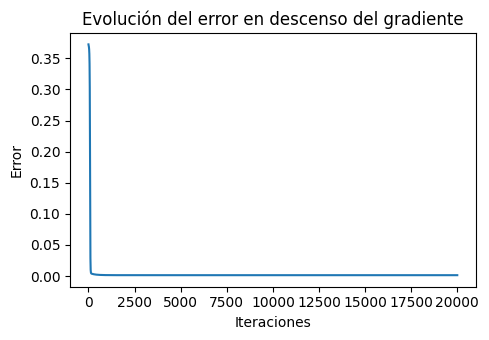

In [ ]:
errores = des_gradiente_evo_error(theta_0, 20000, 1)
iteracion = np.arange(20000)


fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(iteracion, errores, "-", ms=4)
ax.set_xlabel("Iteraciones")
ax.set_ylabel("Error")
ax.set_title("Evolución del error en descenso del gradiente")
fig.tight_layout()
fig.savefig("figuras/evo_des_gradiente.png", dpi=200)
plt.show()

Reducimos el tamaño del grafico para visualizar el cambio en el error

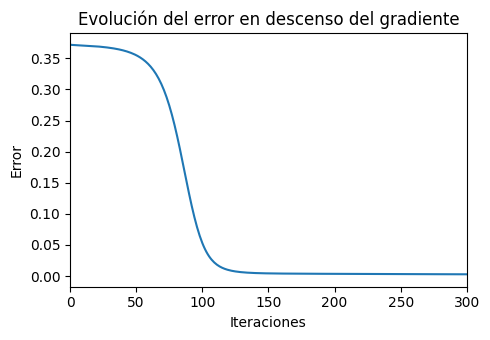

In [88]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(iteracion, errores, "-", ms=4)
ax.set_xlim(0, 300)
ax.set_xlabel("Iteraciones")
ax.set_ylabel("Error")
ax.set_title("Evolución del error en descenso del gradiente")
fig.tight_layout()
fig.savefig("figuras/evo_des_gradiente_cambio.png", dpi=200)
plt.show()

## (e) Parámetros encontrados

Los valores encontrados son:

In [68]:
val_20000 = des_gradiente(theta_0, 20000, 1)
print("θ20.000 es igual a:", val_20000)
print("El error J(θ20.000) es igual a:", J(val_20000))

θ20.000 es igual a: [np.float64(4.760715558315389), np.float64(0.6530972362199524), np.float64(-4.1795939997477465), np.float64(0.6664064578819828), np.float64(3.5015771937145383), np.float64(-0.09019414782443037)]
El error J(θ20.000) es igual a: 0.0013926087275184804


In [ ]:
#gráfico

## (f) Sensibilidad del entrenamiento

### i. Tamaño del paso

Repetimos (d)

In [69]:
error_001 = des_gradiente_evo_error(theta_0, 20000, 0.01)
error_01 = des_gradiente_evo_error(theta_0, 20000, 0.1)
#El paso igual a 1 ya lo calculamos antes
error_1 = errores
error_25 = des_gradiente_evo_error(theta_0, 20000, 2.5)

C:\Users\josem\AppData\Local\Temp\ipykernel_30096\4236339785.py:19: RuntimeWarning: overflow encountered in scalar add
  return sum(e(i, theta)**2)/(2*N)
C:\Users\josem\AppData\Local\Temp\ipykernel_30096\4236339785.py:19: RuntimeWarning: overflow encountered in square
  return sum(e(i, theta)**2)/(2*N)
C:\Users\josem\AppData\Roaming\Python\Python312\site-packages\numpy\_core\fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\josem\AppData\Roaming\Python\Python312\site-packages\numpy\_core\fromnumeric.py:86: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\josem\AppData\Local\Temp\ipykernel_30096\1863901412.py:8: RuntimeWarning: invalid value encountered in scalar subtract
  theta_k[i] = theta_kmin1[i] - paso * theta_temp[i]


Text(0.5, 1.0, 'Cuatro pasos diferentes')

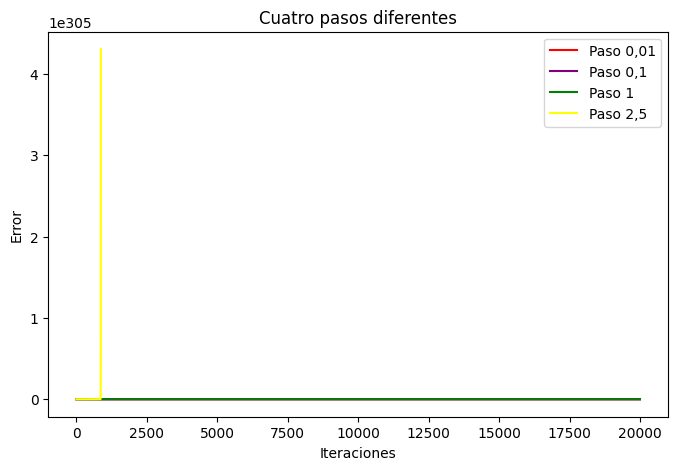

In [78]:
plt.figure(figsize=(8, 5))

plt.plot(iteracion, error_001, color='red', linestyle='-', label='Paso 0,01')
plt.plot(iteracion, error_01, color='purple', linestyle='-', label='Paso 0,1')
plt.plot(iteracion, error_1, color='green', linestyle='-', label='Paso 1')
plt.plot(iteracion, error_25, color='yellow', linestyle='-', label='Paso 2,5')

plt.legend()

plt.xlabel("Iteraciones")
plt.ylabel("Error")

plt.savefig("figuras/cuatro_curvas_error.png", dpi=200)
plt.title("Cuatro pasos diferentes")

Dado que el la línea del paso 2,5 acapara el gráfico, graficamos nuevamente sin incluirla para poder visualizar las demás

Text(0.5, 1.0, 'Tres pasos diferentes')

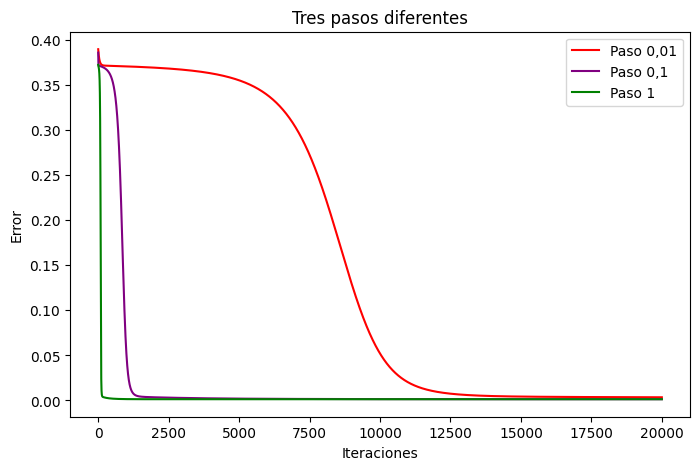

In [86]:
plt.figure(figsize=(8, 5))

plt.plot(iteracion, error_001, color='red', linestyle='-', label='Paso 0,01')
plt.plot(iteracion, error_01, color='purple', linestyle='-', label='Paso 0,1')
plt.plot(iteracion, error_1, color='green', linestyle='-', label='Paso 1')

plt.legend()

plt.xlabel("Iteraciones")
plt.ylabel("Error")

plt.savefig("figuras/tres_curvas_error.png", dpi=200)
plt.title("Tres pasos diferentes")

Cuando el paso es muy grabde, el error aumenta de forma veloz y nunca se acerca al valor esperado, mientras que el paso más pequeño reduce el error lentamente, los pasos más cercanos a 1 parecen ser los que reducen el error a una mayor velocidad

### ii. Distintas inicializaciones

In [87]:
theta_1 = np.random.uniform(-1, 1, 6)
theta_2 = np.random.uniform(-1, 1, 6)
theta_3 = np.random.uniform(-1, 1, 6)
theta_4 = np.random.uniform(-1, 1, 6)
theta_5 = np.random.uniform(-1, 1, 6)
theta_6 = np.random.uniform(-1, 1, 6)
theta_7 = np.random.uniform(-1, 1, 6)
theta_8 = np.random.uniform(-1, 1, 6)
theta_9 = np.random.uniform(-1, 1, 6)
theta_10 = np.random.uniform(-1, 1, 6)

In [ ]:
error_001 = des_gradiente_evo_error(theta_0, 20000, 0.01)
error_01 = des_gradiente_evo_error(theta_0, 20000, 0.1)
#El paso igual a 1 ya lo calculamos antes
error_1 = errores
error_25 = des_gradiente_evo_error(theta_0, 20000, 2.5)

In [ ]:
val_20000 = des_gradiente(theta_0, 20000, 1)

array([-0.35677824, -0.94567918,  0.46571953,  0.26117204,  0.62836479,
        0.03764693])

## (g) Datos de otra función

### i. Entrenamiento con `datos_P2_g.csv`

In [40]:
# TODO

### ii.